# Running PARAFAC analysis in LA community

## pre-processing data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os


JSONL_FILE = '../data/whosampled-brainz-final.jsonl'

import json
from tqdm import tqdm

data = []

with open(JSONL_FILE, 'r', encoding='utf-8') as f:
  for line in tqdm(f,total=311292):

    data.append(json.loads(line))

print(f'existem {len(data)} amostras no arquivo JSONL')


100%|██████████| 311292/311292 [00:06<00:00, 45147.32it/s]

existem 311292 amostras no arquivo JSONL


In [2]:
import pandas as pd

def flatten_data(data):
    rows = []
    for obj in data:
        key = obj['key']
        relation_type = obj['relation_type']
        for direction in ('from', 'to'):
            row = {
                'key': key,
                'relation_type': relation_type,
                'direction': direction,
                **obj[direction]
            }
            rows.append(row)
    return pd.DataFrame(rows)

df = flatten_data(data)
df

,key,relation_type,direction,match_found,artist_searched,music_searched,reference_year,database_artist,database_recording,artist_gid,...,artist_area,artist_area_type,artist_country,release_group_types,n_candidates_original,n_candidates,year_filter_status,years_considered,tags,tags_source_level
0,562023,sampled,from,False,"[Solar (Polish Rapper), Białas]",Nie Pamiętam,2009,NaN,NaN,NaN,...,NaN,NaN,NaN,[],0,0,NaN,[],[],NaN
1,562023,sampled,to,True,[Joe Simon],If,1972,Joe Simon,If,b7635355-a40d-4b08-b441-71aa91017bfd,...,United States,Country,United States,[Album],2,1,exact,"[1972, 2008]","[funk soul, soul]",release
2,584852,sampled,from,True,[Candy Apple],We Got the Funk,1998,Candy Apple,We Got the Funk,ac43968a-567b-49b6-ac92-78e62ec18cf6,...,NaN,NaN,NaN,[Album],1,1,exact,[1999],"[electronic, garage house, house]",release_group
3,584852,sampled,to,True,[Positive Force],We Got the Funk,1980,Positive Force,We Got the Funk,d40925df-080e-4ac4-bcad-325c95a1642b,...,Pennsylvania,Subdivision,United States,"[Album, Single]",50,3,exact,"[2006, 1979, 2000, 1998, 1979, 1988, 1995, 202...","[classical, pop, dance, funk, soul, disco, jaz...",music
4,292396,sampled,from,True,"[Plattenpapzt, Brixx]",Dicks,2000,Brixx,Dicks,dd7d3072-332a-4bad-bd0e-5f038cc3b269,...,Germany,Country,Germany,[Album],1,1,exact,[2000],[hip hop],release_group
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
622579,486815,sampled,to,False,[Kaori Mizuhashi],"Navi ""Listen""",1998,NaN,NaN,NaN,...,NaN,NaN,NaN,[],0,0,NaN,[],[],NaN
622580,437468,sampled,from,False,[Alex Aiono],I Hate You I Love You and Too Good Mashup,2016,NaN,NaN,NaN,...,NaN,NaN,NaN,[],0,0,NaN,[],[],NaN
622581,437468,sampled,to,True,"[Gnash, Olivia O'Brien]","I Hate U, I Love U",2016,gnash,"i hate u, i love u",02f44a81-34f0-4f52-9ab7-c3cfcdb60333,...,United States,Country,United States,"[Album, EP]",14,12,exact,"[2016, 2016, 2017, 2016, 2016, 2016, 2023, 201...","[pop, indie rock, alternative, singer, songwri...",music
622582,437469,sampled,from,False,[Alex Aiono],I Hate You I Love You and Too Good Mashup,2016,NaN,NaN,NaN,...,NaN,NaN,NaN,[],0,0,NaN,[],[],NaN


In [3]:
row_ok = df['match_found'] & df['tags_source_level'].notna() & df['artist_country'].notna() & (df['year_filter_status']=='exact')

# Group by key: True only if BOTH rows satisfy the condition
both_ok = row_ok.groupby(df['key']).all()

good_global_df = df[df['key'].map(both_ok)].copy()
good_global_df

,key,relation_type,direction,match_found,artist_searched,music_searched,reference_year,database_artist,database_recording,artist_gid,...,artist_area,artist_area_type,artist_country,release_group_types,n_candidates_original,n_candidates,year_filter_status,years_considered,tags,tags_source_level
4,292396,sampled,from,True,"[Plattenpapzt, Brixx]",Dicks,2000,Brixx,Dicks,dd7d3072-332a-4bad-bd0e-5f038cc3b269,...,Germany,Country,Germany,[Album],1,1,exact,[2000],[hip hop],release_group
5,292396,sampled,to,True,[Redman],Cloze Ya Door,1998,Redman,Cloze Ya Doors,1f1f6737-b930-46fc-8d25-110bb99f7490,...,United States,Country,United States,[Album],2,2,exact,"[1998, 1998]","[rap, hip hop, east coast hip hop]",music
14,119568,sampled,from,True,[The Away Team],Road to Redemption,2011,The Away Team,The Road to Redemption,c1ff6399-cc88-4ea5-9caa-db250e842cd8,...,United States,Country,United States,[Album],1,1,exact,[2011],[hip hop],release_group
15,119568,sampled,to,True,[Marvin Gaye],I Want You,1976,Marvin Gaye,I Want You,afdb7919-059d-43c1-b668-ba1d265e7e42,...,United States,Country,United States,[Album],23,1,exact,"[2010, 2009, 2008, 2019, 2007, 2007, 1976, 200...","[rock, blues, funk, soul, r b, motown, r&b]",music
18,171184,sampled,from,True,[Zomby],Labyrinth,2011,Zomby,Labyrinth,21a6751e-887e-4eae-9989-de45d452feb6,...,United Kingdom,Country,United Kingdom,[Album],3,2,exact,"[2011, 2011, None]","[dubstep, electronic, breakbeat, techno]",release_group
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
622571,318462,sampled,to,True,[Ice Cube],AmeriKKKa's Most Wanted,1990,Ice Cube,Amerikkka’s Most Wanted,1d11e2a1-4531-4d61-a8c7-7b5c6a608fd2,...,United States,Country,United States,[Album],9,3,exact,"[2005, 2014, 1991, 1990, 2012, 1990, 2013, 201...","[rap, hip hop, gangsta rap, hardcore rap, west...",music
622572,319121,sampled,from,True,[Toddy Tee],I Did So Much Dirt,1992,Toddy Tee,I Did So Much Dirt,4fbe9767-bcb5-4914-9f4c-f451f5861649,...,United States,Country,United States,[Album],2,1,exact,"[1992, None]","[hip hop, west coast hip hop]",artist
622573,319121,sampled,to,True,[Lee Dorsey],"Get Out of My Life, Woman",1966,Lee Dorsey,"Get Out of My Life, Woman",23388f69-9c11-44a6-b832-b9071db3423e,...,United States,Country,United States,[Album],35,2,exact,"[1993, 1999, 2001, 1965, 1991, 2018, 1997, 199...","[hip hop, soul, northern soul, r&b, blues, fun...",music
622574,585884,sampled,from,True,[Death Grips],Hahaha,2018,Death Grips,Hahaha,f9133036-ab3d-4e97-bd11-7a2c98ad148a,...,United States,Country,United States,[Album],1,1,exact,[2018],"[experimental hip hop, noise, electronic, rock...",release_group


In [4]:
# map country names to abbreviations

country_to_abbr = {
    'United States': 'USA',
    'Chile': 'CHL',
    'Brazil': 'BRA',
    'Colombia': 'COL',
    'Canada': 'CAN',
    'Germany': 'DEU',
    'Argentina': 'ARG',
    'Spain': 'ESP',
    'Mexico': 'MEX',
    'Australia': 'AUS',
    'United Kingdom': 'UK',
    'Portugal': 'PRT',
    'Italy': 'ITA',
    'Sweden': 'SWE',
    'Peru': 'PER',
    'Japan': 'JPN',
    'France': 'FRA',
    'Netherlands': 'NLD',
    'Uruguay': 'URY',
    'Jamaica': 'JAM',
    'Belgium': 'BEL',
    'Puerto Rico': 'PRI',
    'Ecuador': 'ECU',
    'Venezuela': 'VEN',
    'Türkiye': 'TUR',
    'Panama': 'PAN',
    'Greece': 'GRC',
    'Norway': 'NOR',
    'Finland': 'FIN',
    'Paraguay': 'PRY',
    'Denmark': 'DNK',
    'Romania': 'ROU',
    'Cuba': 'CUB',
    'Hungary': 'HUN',
    'New Zealand': 'NZL',
    'Iceland': 'ISL',
    'Poland': 'POL',
    'Suriname': 'SUR',
    'Austria': 'AUT',
    'Honduras': 'HND',
    'Morocco': 'MAR',
    'Philippines': 'PHL',
    'Israel': 'ISR',
    'Switzerland': 'CHE',
    'Serbia': 'SRB',
    'Nigeria': 'NGA',
    'Ireland': 'IRL',
    'Dominican Republic': 'DOM',
    'South Korea': 'KOR',
    'South Africa': 'ZAF',
    'Monaco': 'MCO',
}

good_global_df['artist_country_abb'] = good_global_df['artist_country'].map(country_to_abbr)

In [5]:
north_america = [
    'United States', 'Canada', 'Greenland'
]

latin_america = [
    'Chile', 'Colombia', 'Brazil', 'Argentina', 'Mexico', 'Peru',
    'Uruguay', 'Ecuador', 'Venezuela', 'Panama', 'Paraguay', 'Honduras',
    'Suriname'
]

caribbean = [
    'Jamaica', 'Bahamas', 'Puerto Rico', 'Haiti', 'Cuba',
    'Trinidad and Tobago', 'Dominican Republic', 'Antigua and Barbuda',
    'Guadeloupe', 'Montserrat', 'U.S. Virgin Islands', 'Grenada',
    'British Virgin Islands', 'Barbados', 'Martinique',
    'Saint Vincent and The Grenadines'
]

middle_east = [
    'Türkiye', 'Israel', 'Jordan', 'Lebanon', 'Iran',
    'United Arab Emirates', 'Bahrain', 'Saudi Arabia', 'Syria'
]

europe = [
    'Germany', 'United Kingdom', 'France', 'Italy', 'Croatia',
    'Netherlands', 'Poland', 'Sweden', 'Belgium', 'Norway', 'Spain',
    'Bosnia and Herzegovina', 'Romania', 'Austria', 'Iceland', 'Ireland',
    'Finland', 'Hungary', 'Russia', 'Switzerland', 'Estonia', 'Czechia',
    'Denmark', 'Kingdom of the Netherlands', 'Portugal', 'Serbia',
    'Monaco', 'Latvia', 'Slovakia', 'Greece', 'Slovenia', 'Lithuania',
    'Yugoslavia', 'Montenegro', 'Czechoslovakia', 'Ukraine', 'Bulgaria',
    'Malta', 'Moldova', 'Jersey', 'Belarus', 'East Germany', 'Kosovo',
    'North Macedonia'
]

asia = [
    'Japan', 'South Korea', 'India', 'China', 'Philippines', 'Singapore',
    'Vietnam', 'Taiwan', 'Thailand', 'Malaysia', 'Pakistan', 'Azerbaijan',
    'Kazakhstan', 'Indonesia', 'Afghanistan'
]

africa = [
    'South Africa', 'Nigeria', 'Cameroon', 'Zimbabwe', 'Ethiopia',
    'Guinea', 'Morocco', 'Kenya', 'Senegal', "Côte d'Ivoire", 'Tanzania',
    'Ghana', 'Algeria', 'Mali', 'Mozambique', 'Congo', 'Zambia', 'Egypt',
    'Angola', 'Burkina Faso', 'Réunion', 'Niger',
    'Democratic Republic of the Congo', 'Somalia', 'Gambia', 'Madagascar'
]

oceania = [
    'New Zealand', 'Australia', 'Fiji'
]

regioes = {
    'north_america': north_america,
    'latin_america': latin_america,
    'caribbean': caribbean,
    'middle_east': middle_east,
    'europe': europe,
    'asia': asia,
    'africa': africa,
    'oceania': oceania,
}

pais_para_regiao = {
    pais: regiao
    for regiao, paises in regioes.items()
    for pais in paises
}

good_global_df['regional_group'] = good_global_df['artist_country'].map(pais_para_regiao)

In [6]:
#mask = good_global_df.groupby('key')['regional_group'].transform(lambda x: ((x == 'latin_america') | (x == 'caribbean')).any())
mask = good_global_df.groupby('key')['regional_group'].transform(lambda x: (x == 'latin_america').any())
good_latins_df = good_global_df[mask]
good_latins_df

,key,relation_type,direction,match_found,artist_searched,music_searched,reference_year,database_artist,database_recording,artist_gid,...,artist_country,release_group_types,n_candidates_original,n_candidates,year_filter_status,years_considered,tags,tags_source_level,artist_country_abb,regional_group
126,64766,sampled,from,True,"[Havoc, CurT@!n$, Myth]",Guerilla War,2010,Havoc,Gureilla War,cbbc6253-efea-4cc7-a279-f3ad348f6744,...,United States,[Other],1,1,exact,[2010],"[hip hop, east coast hip hop]",artist,USA,north_america
127,64766,sampled,to,True,[Los Angeles Negros],No Morira Jamas,1971,Los Ángeles Negros,No morirá jamás,3febb873-0757-47a2-b9cb-baa2cf0e5b91,...,Chile,[Album],6,2,exact,"[1996, 1996, 1972, 2015, 1971, 2016]","[latin, psychedelic rock, rock]",release_group,CHL,latin_america
520,175531,sampled,from,True,"[Fortuna, Satenig]",O Fortuna,1991,Fortuna,O Fortuna,6fc5accc-f523-4a31-b84f-8c9955311872,...,Brazil,[Album],2,2,exact,"[1992, 1992]","[ebm, electronic, new beat, techno, euro house...",release_group,BRA,latin_america
521,175531,sampled,to,True,[Raze],Break 4 Love,1987,Raze,Break 4 Love,0a332ba6-e8d6-46ca-9588-b6644516c951,...,United States,"[Album, EP, Single]",43,1,exact,"[2013, 2019, 1996, 1989, 2019, 1994, 2017, 200...","[electronic, soundtrack, dance, house, deep ho...",music,USA,north_america
942,634526,sampled,from,True,[Djonga],MLK 4TR3VID0,2019,Djonga,Mlk 4tr3v1d0,7228b556-4896-4255-9323-a78bcb42f528,...,Brazil,[Album],1,1,exact,[2019],[rap],release,BRA,latin_america
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
621991,3935,sampled,to,True,[La Sonora Santanera],La Boa,1992,La Sonora Santanera,La boa,7a273984-edd9-4451-9c4d-39b38f05ebcd,...,Mexico,[Album],9,1,exact,"[1992, 2016, 2015, 2002, 2013, 2012, 2013, 199...","[latin, mambo, salsa]",release_group,MEX,latin_america
622190,597397,sampled,from,True,[Cujo],Popsicle,2002,Cujo,Popsicle,2b87a2be-702d-44b3-a1a6-5d111a5d8e52,...,Brazil,[Album],5,2,exact,"[2002, 2004, 2003, 2013, 2005]","[electronic, drum and bass, idm, breakbeat, tr...",music,BRA,latin_america
622191,597397,sampled,to,True,[Ernest Gold],Theme of Exodus,1961,Ernest Gold,Theme of Exodus,4eec4d77-8e33-412f-b2c8-bbdab4702e46,...,United States,"[Album, EP]",6,3,exact,"[1961, 1995, 2011, None, 1960, 1960]","[soundtrack, classical, pop]",music,USA,north_america
622448,497891,sampled,from,True,[LAO],Identity Ha,2017,Lao,Identity Ha,5e2b7c4b-a8c9-42cd-b06c-a366e9e67917,...,Mexico,[EP],1,1,exact,[2017],"[club, mexico city, n.a.a.f.i., naafi]",release,MEX,latin_america


In [7]:
# gera dataset com informações concisas

from_df = good_latins_df[good_latins_df['direction'] == 'from'][
    ['key', 'artist_country', 'tags', 'release_year']
].rename(columns={
    'artist_country': 'artist_country_from',
    'tags': 'tags_from',
})

to_df = good_latins_df[good_latins_df['direction'] == 'to'][
    ['key', 'artist_country', 'tags']
].rename(columns={
    'artist_country': 'artist_country_to',
    'tags': 'tags_to',
})

merged_latins_df = from_df.merge(to_df, on='key', how='inner')
merged_latins_df

,key,artist_country_from,tags_from,release_year,artist_country_to,tags_to
0,64766,United States,"[hip hop, east coast hip hop]",2010.0,Chile,"[latin, psychedelic rock, rock]"
1,175531,Brazil,"[ebm, electronic, new beat, techno, euro house...",1992.0,United States,"[electronic, soundtrack, dance, house, deep ho..."
2,634526,Brazil,[rap],2019.0,Brazil,"[mpb, samba, pagode]"
3,165019,Chile,"[funk, rock]",1997.0,United States,"[funk, soul, r&b, classic soul]"
4,104689,United States,"[christian, hip hop, christian rock, conscious...",2002.0,Colombia,"[electronic, latin, latin dance]"
...,...,...,...,...,...,...
2064,595044,United States,[hip hop],2018.0,Colombia,"[downtempo, trip hop]"
2065,558458,Brazil,[drum and bass],2007.0,United Kingdom,"[electronic, drum and bass]"
2066,3935,United States,"[rap, latin]",2004.0,Mexico,"[latin, mambo, salsa]"
2067,597397,Brazil,"[electronic, drum and bass, idm, breakbeat, tr...",2002.0,United States,"[soundtrack, classical, pop]"


In [8]:
merged_latins_tags_df = merged_latins_df.explode('tags_from').explode('tags_to')
merged_latins_tags_df

,key,artist_country_from,tags_from,release_year,artist_country_to,tags_to
0,64766,United States,hip hop,2010.0,Chile,latin
0,64766,United States,hip hop,2010.0,Chile,psychedelic rock
0,64766,United States,hip hop,2010.0,Chile,rock
0,64766,United States,east coast hip hop,2010.0,Chile,latin
0,64766,United States,east coast hip hop,2010.0,Chile,psychedelic rock
...,...,...,...,...,...,...
2068,497891,Mexico,naafi,2017.0,United States,house
2068,497891,Mexico,naafi,2017.0,United States,adult contemporary
2068,497891,Mexico,naafi,2017.0,United States,hip hop
2068,497891,Mexico,naafi,2017.0,United States,breakbeat


## PARAFAC

In [9]:
from collections import Counter
tensor_counts = Counter()

for key, group in tqdm(good_latins_df.groupby('key')):

    from_data = group[group['direction'] == 'from'].iloc[0]
    to_data = group[group['direction'] == 'to'].iloc[0]


    assert from_data.get("match_found") and to_data.get("match_found"), 'Match_not_found!'

    country_from = from_data.get("artist_country")
    country_to = to_data.get("artist_country")

    assert country_from in latin_america or country_to in latin_america, 'algum dos paises not in LA'

    #assert country_from != country_to, 'self-loop!'

    tags_from = {
        tag.strip()
        for tag in from_data.get("tags", [])
        if tag and tag.strip()
    }

    tags_to = {
        tag.strip()
        for tag in to_data.get("tags", [])
        if tag and tag.strip()
    }


    assert tags_from != [] and tags_to != [], 'tags vazia'
    # if not tags_from or not tags_to:
    #     continue

    year_from = from_data.get("release_year")

    if (year_from is None) or (year_from >= 2020):
        continue

    year_from = int(year_from)

    for tag_from in tags_from:
        for tag_to in tags_to:
            tensor_counts[
                (
                    country_from,
                    country_to,
                    tag_from,
                    tag_to,
                    year_from,
                )
            ] += 1

print(f"Non-zero entries: {len(tensor_counts):,}")

100%|██████████| 2069/2069 [00:01<00:00, 1176.33it/s]

Non-zero entries: 46,181


In [10]:
tensor_counts.most_common(n=20)

[(('Brazil', 'United States', 'hip hop', 'soul', 1997), 20),
 (('Brazil', 'United States', 'hip hop', 'funk', 1997), 17),
 (('United States', 'Brazil', 'hip hop', 'latin', 2014), 16),
 (('United States', 'Brazil', 'hip hop', 'latin', 2012), 15),
 (('Brazil', 'United States', 'hip hop', 'r&b', 1997), 14),
 (('Brazil', 'United States', 'hip hop', 'soul', 1999), 13),
 (('Brazil', 'United States', 'latin', 'soul', 1997), 12),
 (('United States', 'Brazil', 'hip hop', 'mpb', 2012), 12),
 (('United States', 'Brazil', 'hip hop', 'latin', 2013), 12),
 (('United States', 'Brazil', 'hip hop', 'jazz', 2014), 12),
 (('Brazil', 'United States', 'future funk', 'soul', 2016), 12),
 (('Brazil', 'United States', 'hip hop', 'r&b', 1999), 11),
 (('Brazil', 'United States', 'hip hop', 'funk', 1999), 11),
 (('United States', 'Brazil', 'hip hop', 'mpb', 2009), 11),
 (('Brazil', 'United States', 'hip hop', 'funk', 1990), 11),
 (('United States', 'Brazil', 'hip hop', 'mpb', 2014), 11),
 (('Brazil', 'United Sta

In [11]:
VALID_COUNTRIES = good_latins_df.artist_country.unique()
countries_5d = sorted(VALID_COUNTRIES)

country_to_idx_5d = {
    country: i
    for i, country in enumerate(countries_5d)
}

tags_from_5d = sorted({
    tag_from
    for (
        country_from,
        country_to,
        tag_from,
        tag_to,
        year_from,
    ) in tensor_counts
})

tags_to_5d = sorted({
    tag_to
    for (
        country_from,
        country_to,
        tag_from,
        tag_to,
        year_from,
    ) in tensor_counts
})

tag_from_to_idx = {
    tag: i
    for i, tag in enumerate(tags_from_5d)
}

tag_to_to_idx = {
    tag: i
    for i, tag in enumerate(tags_to_5d)
}

years_5d = sorted({
    year_from
    for (
        country_from,
        country_to,
        tag_from,
        tag_to,
        year_from,
    ) in tensor_counts
})

year_to_idx_5d = {
    year: i
    for i, year in enumerate(years_5d)
}

print(f"Countries: {len(countries_5d):,}")
print(f"Tags from: {len(tags_from_5d):,}")
print(f"Tags to: {len(tags_to_5d):,}")
print(f"Years: {len(years_5d):,}")

Countries: 51
Tags from: 1,123
Tags to: 1,108
Years: 54


In [12]:
import torch

torch.sparse.check_sparse_tensor_invariants.enable()

indices_5d = []
values_5d = []

for (
    country_from,
    country_to,
    tag_from,
    tag_to,
    year_from,
), count in tensor_counts.items():



    indices_5d.append([
        country_to_idx_5d[country_from],
        country_to_idx_5d[country_to],
        tag_from_to_idx[tag_from],
        tag_to_to_idx[tag_to],
        year_to_idx_5d[year_from],
    ])

    values_5d.append(float(count))

indices_5d = torch.tensor(
    indices_5d,
    dtype=torch.long
).T

values_5d = torch.tensor(
    values_5d,
    dtype=torch.float32
)

shape_5d = (
    len(countries_5d),
    len(countries_5d),
    len(tags_from_5d),
    len(tags_to_5d),
    len(years_5d),
)

X5 = torch.sparse_coo_tensor(
    indices_5d,
    values_5d,
    size=shape_5d,
).coalesce()

print("Shape:", tuple(X5.shape))
print("Non-zero:", X5._nnz())
print("Total:", X5.numel())
print("Density:", X5._nnz() / X5.numel())

Shape: (51, 51, 1123, 1108, 54)
Non-zero: 46181
Total: 174764664936
Density: 2.642467801881564e-07


In [13]:
import torch.nn as nn
import torch.nn.functional as F

class PARAFAC5(nn.Module):

    def __init__(
        self,
        n_country_from,
        n_country_to,
        n_tag_from,
        n_tag_to,
        n_years,
        rank,
        device=None,
        dtype=torch.float32,
    ):
        super().__init__()

        self.rank = rank

        init_shift = -3.0  # softplus(-5) ≈ 0.0067

        self.A = nn.Parameter(
            init_shift + 0.01 * torch.randn(n_country_from, rank, device=device, dtype=dtype)
        )

        self.B = nn.Parameter(
            init_shift + 0.01 * torch.randn(n_country_to, rank, device=device, dtype=dtype)
        )

        self.C = nn.Parameter(
            init_shift + 0.01 * torch.randn(n_tag_from, rank, device=device, dtype=dtype)
        )

        self.D = nn.Parameter(
            init_shift + 0.01 * torch.randn(n_tag_to, rank, device=device, dtype=dtype)
        )

        self.E = nn.Parameter(
            init_shift + 0.01 * torch.randn(n_years, rank, device=device, dtype=dtype)
        )


    @property
    def factors(self):
        A = F.softplus(self.A)
        B = F.softplus(self.B)
        C = F.softplus(self.C)
        D = F.softplus(self.D)
        E = F.softplus(self.E)

        return A, B, C, D, E

    def predict_entries(self, indices):

        A, B, C, D, E = self.factors

        i = indices[0]
        j = indices[1]
        k = indices[2]
        l = indices[3]
        m = indices[4]

        return (
            A[i]
            * B[j]
            * C[k]
            * D[l]
            * E[m]
        ).sum(dim=1)

    def reconstruction_norm_squared(self):

        A, B, C, D, E = self.factors

        gram = (
            (A.T @ A)
            * (B.T @ B)
            * (C.T @ C)
            * (D.T @ D)
            * (E.T @ E)
        )

        return (
            gram
        ).sum()

In [14]:
def parafac5_loss(model, X, excluded_indices=None):

    # excluded_indices: cells (5, n) that must not enter the loss at all
    # (e.g. validation cells). Without this, cells missing from X are treated
    # as zeros by the ||X_hat||^2 term.

    X = X.coalesce()

    indices = X.indices()
    values = X.values()

    predictions = model.predict_entries(indices)

    x_norm_squared = values.square().sum()

    cross = (values * predictions).sum()

    reconstruction_norm_squared = (
        model.reconstruction_norm_squared()
    )

    # remove the excluded cells from ||X_hat||^2 (sum over all cells)
    if excluded_indices is not None:
        reconstruction_norm_squared = (
            reconstruction_norm_squared
            - model.predict_entries(excluded_indices).square().sum()
        )

    return (
        x_norm_squared
        - 2.0 * cross
        + reconstruction_norm_squared
    )

In [15]:
def fit_parafac5(
    X,
    rank=10,
    epochs=2000,
    lr=1e-2,
    verbose=True,
    excluded_indices=None,
):

    X = X.coalesce()

    device = X.device
    dtype = X.values().dtype

    model = PARAFAC5(
        n_country_from=X.shape[0],
        n_country_to=X.shape[1],
        n_tag_from=X.shape[2],
        n_tag_to=X.shape[3],
        n_years=X.shape[4],
        rank=rank,
        device=device,
        dtype=dtype,
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
    )

    x_norm_squared = (
        X.values().square().sum()
    ).detach()

    for epoch in range(epochs):

        optimizer.zero_grad()

        loss = parafac5_loss(model, X, excluded_indices=excluded_indices)

        relative_loss = (
            loss /
            x_norm_squared.clamp_min(1e-12)
        )

        relative_loss.backward()

        optimizer.step()

        if verbose and (
            epoch == 0
            or (epoch + 1) % 100 == 0
            or epoch == epochs - 1
        ):

            error = (
                relative_loss
                .detach()
                .clamp_min(0)
                .sqrt()
            )

            print(
                f"Epoch {epoch + 1:5d} | "
                f"Loss: {loss.item():.4e} | "
                f"Relative error: {error.item():.6f}"
            )

    return model

In [16]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import time

def evaluate_parafac_ranks(
    X,
    ranks=[2, 3, 4, 5, 6, 8, 10, 12, 15],
    n_folds=5,
    epochs=1000,
    lr=1e-2,
    seed=42
):
    """
    Evaluates PARAFAC rank candidates using k-fold cross-validation on observed entries.
    """
    torch.manual_seed(seed)
    X = X.coalesce()

    indices = X.indices()
    values = X.values()
    nnz = values.shape[0]

    # 1. Split observed entries into n_folds random folds
    perm = torch.randperm(nnz)
    folds = perm.chunk(n_folds)

    results = []

    print(f"{'Rank':>5} | {'Train Rel Loss':>15} | {'Val RE (mean)':>15} | {'Val RE (std)':>15} | {'Time spent':>15}")
    print("-" * 80)

    for r in ranks:

        train_res = []
        val_res = []

        start_time = time.perf_counter()

        for f in range(n_folds):

            # fold f is the validation set, the other folds are the training set
            val_idx_mask = folds[f]
            train_idx_mask = torch.cat([folds[g] for g in range(n_folds) if g != f])

            train_indices = indices[:, train_idx_mask]
            train_values = values[train_idx_mask]

            val_indices = indices[:, val_idx_mask]
            val_values = values[val_idx_mask]

            X_train = torch.sparse_coo_tensor(
                train_indices, train_values, size=X.shape, device=X.device
            ).coalesce()

            model = fit_parafac5(
                X_train,
                rank=r,
                epochs=epochs,
                lr=lr,
                verbose=False,
                excluded_indices=val_indices,  # validation cells are not treated as zeros
            )
            model.eval()

            with torch.no_grad():
                train_loss = parafac5_loss(model, X_train, excluded_indices=val_indices).item()
                train_res.append(np.sqrt(max(0, train_loss / train_values.square().sum().item())))

                val_pred = model.predict_entries(val_indices)
                val_mse = (val_values - val_pred).square().sum().item()
                val_res.append(np.sqrt(val_mse / val_values.square().sum().clamp_min(1e-12).item()))

        if torch.cuda.is_available():
          torch.cuda.synchronize()

        end_time = time.perf_counter()
        elapsed_time = end_time - start_time

        results.append({
            "rank": r,
            "train_rel_error": np.mean(train_res),
            "val_rel_error": np.mean(val_res),
            "val_rel_error_std": np.std(val_res),
            "time_spent": elapsed_time
        })

        print(f"{r:5d} | {np.mean(train_res):15.4f} | {np.mean(val_res):15.4f} | {np.std(val_res):15.4f} | {elapsed_time:.4f} ")

    return results


def second_derivative_rank(ranks, errors):
    """
    Discrete second derivative of the validation error with non-uniform rank spacing.
    Returns the interior ranks, their second derivatives and the rank with the maximum value.
    """
    r = np.asarray(ranks, dtype=float)
    e = np.asarray(errors, dtype=float)

    h1 = r[1:-1] - r[:-2]   # distance to the previous rank
    h2 = r[2:] - r[1:-1]    # distance to the next rank

    d2 = 2.0 * (h1 * e[2:] - (h1 + h2) * e[1:-1] + h2 * e[:-2]) / (h1 * h2 * (h1 + h2))

    best_rank = int(r[1:-1][np.argmax(d2)])

    return r[1:-1], d2, best_rank

In [17]:
window_half = 2  # janela de 5 anos total: [y-2, y+2]

indices_5d = []
values_5d = []

n_years = len(years_5d)

for (
    country_from,
    country_to,
    tag_from,
    tag_to,
    year_from,
), count in tensor_counts.items():

    i = country_to_idx_5d[country_from]
    j = country_to_idx_5d[country_to]
    k = tag_from_to_idx[tag_from]
    l = tag_to_to_idx[tag_to]
    m_center = year_to_idx_5d[year_from]

    # espalha a contagem em uma janela ao redor do ano central
    m_start = max(0, m_center - window_half)
    m_end = min(n_years, m_center + window_half + 1)

    for m in range(m_start, m_end):
        indices_5d.append([i, j, k, l, m])
        values_5d.append(float(count))

indices_5d = torch.tensor(indices_5d, dtype=torch.long).T
values_5d = torch.tensor(values_5d, dtype=torch.float32)

X5 = torch.sparse_coo_tensor(
    indices_5d,
    values_5d,
    size=shape_5d,
).coalesce()   # <-- aqui as duplicatas somam

In [18]:

values = X5.values()
indices = X5.indices()

# ordena por valor decrescente e pega top-20
top_k = 40
sorted_idx = torch.argsort(values, descending=True)[:top_k]

# maps inversos pra recuperar os nomes
idx_to_country = {i: c for c, i in country_to_idx_5d.items()}
idx_to_tag_from = {i: t for t, i in tag_from_to_idx.items()}
idx_to_tag_to = {i: t for t, i in tag_to_to_idx.items()}
idx_to_year = {i: y for y, i in year_to_idx_5d.items()}

for pos in sorted_idx:
    i, j, k, l, m = indices[:, pos].tolist()
    v = values[pos].item()
    print(f"({idx_to_country[i]!r}, {idx_to_country[j]!r}, "
          f"{idx_to_tag_from[k]!r}, {idx_to_tag_to[l]!r}, "
          f"{idx_to_year[m]}) → {v:.1f}")

('United States', 'Brazil', 'hip hop', 'latin', 2012) → 55.0
('United States', 'Brazil', 'hip hop', 'latin', 2014) → 54.0
('United States', 'Brazil', 'hip hop', 'latin', 2013) → 53.0
('United States', 'Brazil', 'hip hop', 'latin', 2011) → 49.0
('United States', 'Brazil', 'hip hop', 'latin', 2015) → 46.0
('United States', 'Brazil', 'hip hop', 'latin', 2010) → 45.0
('United States', 'Brazil', 'hip hop', 'latin', 2007) → 43.0
('United States', 'Brazil', 'hip hop', 'latin', 2016) → 43.0
('United States', 'Brazil', 'hip hop', 'jazz', 2012) → 42.0
('United States', 'Brazil', 'hip hop', 'latin', 2008) → 41.0
('United States', 'Brazil', 'hip hop', 'jazz', 2013) → 41.0
('Brazil', 'United States', 'hip hop', 'soul', 1998) → 40.0
('United States', 'Brazil', 'hip hop', 'mpb', 2011) → 39.0
('Brazil', 'United States', 'hip hop', 'soul', 1999) → 39.0
('Brazil', 'United States', 'hip hop', 'soul', 1997) → 39.0
('United States', 'Brazil', 'hip hop', 'jazz', 2014) → 39.0
('United States', 'Brazil', 'hip

In [19]:
# device = (
#     "cuda"
#     if torch.cuda.is_available()
#     else "cpu"
# )

device = "cpu"

# Garante que está no formato COO coalescido
X5 = X5.coalesce()

indices = X5.indices()   # shape: (5, nnz)
values = X5.values()     # shape: (nnz,)

# Baseline: o próprio X5
X_raw = X5

# Log1p: aplica só nos valores não-nulos
X_log = torch.sparse_coo_tensor(
    indices,
    torch.log1p(values),
    size=X5.shape,
).coalesce()

# Log1p + threshold ≥ 2: filtra os valores primeiro
mask = values >= 2
X_thresh = torch.sparse_coo_tensor(
    indices[:, mask],
    torch.log1p(values[mask]),
    size=X5.shape,
).to(device).coalesce()

 Rank |  Train Rel Loss |   Val RE (mean) |    Val RE (std) |      Time spent
--------------------------------------------------------------------------------
    2 |          0.9031 |          0.8746 |          0.0030 | 33.0968 
    3 |          0.8861 |          0.8560 |          0.0122 | 33.2051 
    4 |          0.8710 |          0.8406 |          0.0130 | 38.8390 
    5 |          0.8478 |          0.8149 |          0.0106 | 40.6897 
    6 |          0.8411 |          0.8089 |          0.0194 | 41.8496 
    7 |          0.8204 |          0.7840 |          0.0087 | 49.7103 
    8 |          0.8093 |          0.7734 |          0.0094 | 59.8755 
    9 |          0.7947 |          0.7558 |          0.0075 | 59.4144 
   10 |          0.7912 |          0.7570 |          0.0022 | 68.8169 
   11 |          0.7856 |          0.7491 |          0.0057 | 75.9398 
   12 |          0.7795 |          0.7410 |          0.0053 | 80.7415 
   13 |          0.7742 |          0.7377 |          0.0118 

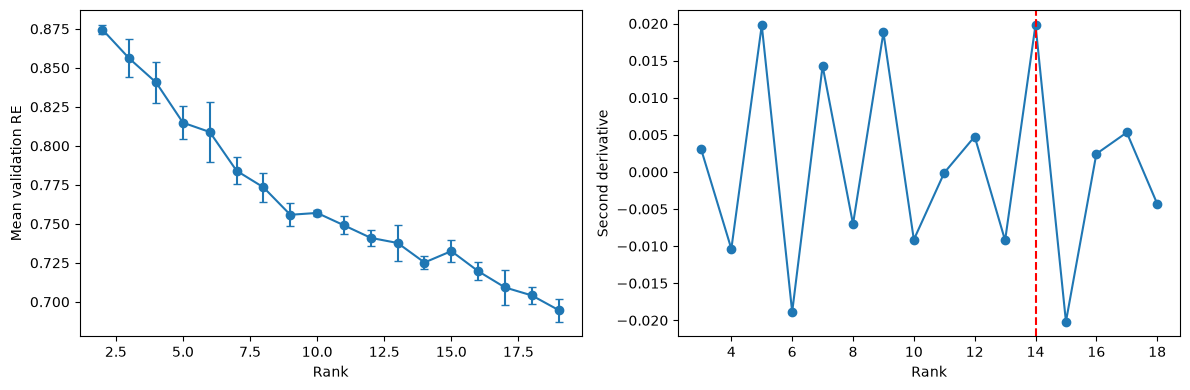

In [20]:
# Rank selection: 5-fold CV + discrete second-derivative criterion
# ranks = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20]
ranks = list(range(2,20))
cv_results = evaluate_parafac_ranks(X_thresh, ranks=ranks, n_folds=5, epochs=1000, lr=1e-2)

val_mean = [res["val_rel_error"] for res in cv_results]
val_std = [res["val_rel_error_std"] for res in cv_results]

d2_ranks, d2, best_rank = second_derivative_rank(ranks, val_mean)
print(f"Selected rank (max second derivative): {best_rank}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].errorbar(ranks, val_mean, yerr=val_std, marker="o", capsize=3)
axes[0].set_xlabel("Rank")
axes[0].set_ylabel("Mean validation RE")

axes[1].plot(d2_ranks, d2, marker="o")
axes[1].axvline(best_rank, color="red", linestyle="--")
axes[1].set_xlabel("Rank")
axes[1].set_ylabel("Second derivative")

plt.tight_layout()
plt.show()

 Rank |     Val RE |    1st deriv |    2nd deriv
--------------------------------------------------
    2 |     0.8746 |    -0.018539 |            -
    3 |     0.8560 |    -0.016965 |     0.003147
    4 |     0.8406 |    -0.020576 |    -0.010368
    5 |     0.8149 |    -0.015879 |     0.019763
    6 |     0.8089 |    -0.015434 |    -0.018873
    7 |     0.7840 |    -0.017729 |     0.014282
    8 |     0.7734 |    -0.014097 |    -0.007018
    9 |     0.7558 |    -0.008210 |     0.018792
   10 |     0.7570 |    -0.003377 |    -0.009125
   11 |     0.7491 |    -0.007994 |    -0.000110
   12 |     0.7410 |    -0.005665 |     0.004769
   13 |     0.7377 |    -0.007895 |    -0.009231
   14 |     0.7252 |    -0.002601 |     0.019820
   15 |     0.7325 |    -0.002779 |    -0.020177
   16 |     0.7197 |    -0.011652 |     0.002431
   17 |     0.7092 |    -0.007780 |     0.005314
   18 |     0.7041 |    -0.007266 |    -0.004287
   19 |     0.6947 |    -0.009409 |            -


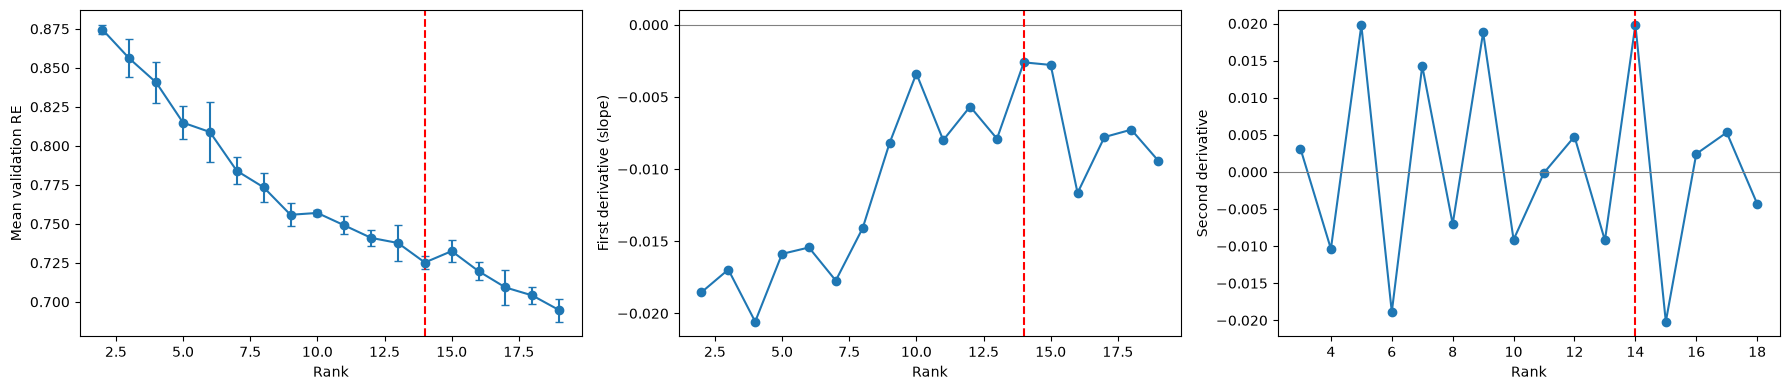

In [21]:
# Elbow analysis: first and second derivatives of the mean validation RE
# (uses cv_results from the cell above, no need to rerun the CV)

r_arr = np.asarray(ranks, dtype=float)
e_arr = np.asarray(val_mean, dtype=float)

# first derivative: central differences with non-uniform spacing (one-sided at the edges)
d1 = np.gradient(e_arr, r_arr)

print(f"{'Rank':>5} | {'Val RE':>10} | {'1st deriv':>12} | {'2nd deriv':>12}")
print("-" * 50)
d2_by_rank = dict(zip(d2_ranks.astype(int), d2))
for r, e, g in zip(ranks, e_arr, d1):
    d2_str = f"{d2_by_rank[r]:12.6f}" if r in d2_by_rank else f"{'-':>12}"
    print(f"{r:5d} | {e:10.4f} | {g:12.6f} | {d2_str}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].errorbar(ranks, val_mean, yerr=val_std, marker="o", capsize=3)
axes[0].set_ylabel("Mean validation RE")

axes[1].plot(ranks, d1, marker="o")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_ylabel("First derivative (slope)")

axes[2].plot(d2_ranks, d2, marker="o")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylabel("Second derivative")

for ax in axes:
    ax.axvline(best_rank, color="red", linestyle="--")
    ax.set_xlabel("Rank")

plt.tight_layout()
plt.show()

In [20]:
# torch.manual_seed(42)
# model_raw = fit_parafac5(X_raw, rank=10, epochs=2000, lr=1e-2, verbose=True)

# torch.manual_seed(42)
# model_log = fit_parafac5(X_log, rank=10, epochs=2000, lr=1e-2, verbose=True)

torch.manual_seed(42)
n_componentes = 15
model_thresh = fit_parafac5(X_thresh, rank=n_componentes, epochs=1000, lr=1e-2, verbose=True)

Epoch     1 | Loss: 4.2776e+04 | Relative error: 1.000031
Epoch   100 | Loss: 4.2770e+04 | Relative error: 0.999963
Epoch   200 | Loss: 3.9344e+04 | Relative error: 0.959084
Epoch   300 | Loss: 3.0740e+04 | Relative error: 0.847749
Epoch   400 | Loss: 2.8358e+04 | Relative error: 0.814243
Epoch   500 | Loss: 2.6425e+04 | Relative error: 0.786003
Epoch   600 | Loss: 2.5724e+04 | Relative error: 0.775507
Epoch   700 | Loss: 2.5349e+04 | Relative error: 0.769833
Epoch   800 | Loss: 2.4958e+04 | Relative error: 0.763867
Epoch   900 | Loss: 2.4294e+04 | Relative error: 0.753647
Epoch  1000 | Loss: 2.4236e+04 | Relative error: 0.752742


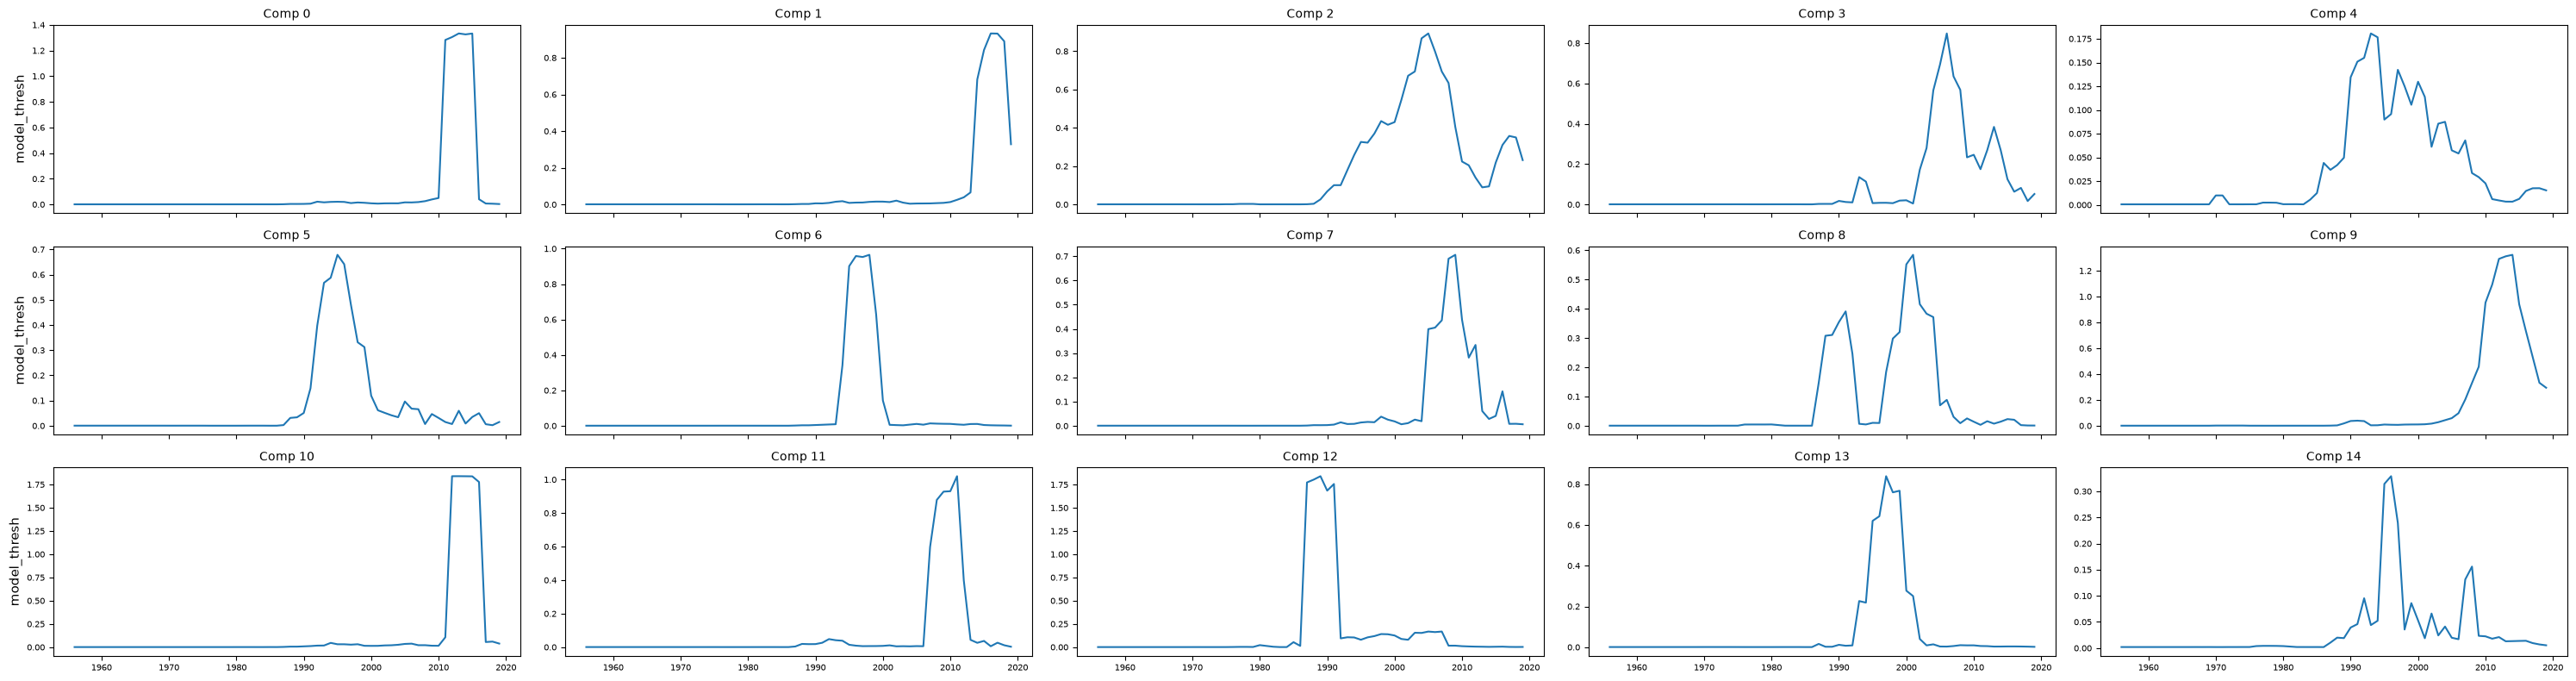

In [21]:
n_rows = int(np.ceil(n_componentes / 5))
fig, axes = plt.subplots(n_rows, 5, figsize=(30, 8 * n_rows / 3), sharex=True, squeeze=False)

used_model = model_thresh

with torch.no_grad():
    E = used_model.factors[4].cpu().numpy()

axes_flat = axes.flatten()

for c in range(n_componentes):
    axes_flat[c].plot(years_5d, E[:, c])
    axes_flat[c].tick_params(axis='both', labelsize=7)
    axes_flat[c].set_title(f"Comp {c}", fontsize=10)

for ax in axes_flat[n_componentes:]:
    ax.set_visible(False)

for row in range(n_rows):
    axes[row, 0].set_ylabel("model_thresh", fontsize=11)

plt.tight_layout()
plt.show()